<a href="https://colab.research.google.com/github/mcundins/cse6242-project/blob/KMeansModel/kmeans_modeling/kmeans_food_desert_risk_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-means clustering (unsupervised learning)

Training model on 2019 dataset

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import pickle

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


| Variable | Description |
|----------|-------------|
|tract_id | census tract number |
|Urban | flag for urban tract |
|Pop2010 | population count from 2010 census |
|OHU2010 | occupied housing unit count from 2010 census |
|GroupQuartersFlag | flag for tract where >=67%; group quarters, tract with high share |
|NUMGQTRS | count of tract population residing in group quarters |
|PCTGQTRS | percent of tract population residing in group quarters |
|LowIncomeTracts | flag for low income tract |
|PovertyRate | share of the tract population living with income at or below the Federal poverty thresholds for family size |
|MedianFamilyIncome | tract median family income |
|TractLOWI | total count of low-income population in tract |
|TractKids | total count of children age 0-17 in tract |
|TractSeniors | total count of seniors age 65+ in tract |
|TractWhite | total count of white population in tract |
|TractBlack | total count of black or african american population in tract |
|TractAsian | total count of asian population in tract |
|TractNHOPI | total count of native hawaiian and other pacific islander population in tract |
|TractAIAN | total count of american indian and alaska native population in tract |
|TractOMultir | total count of other/multiple race population in tract |
|TractHispanic | total count of hispanic or latino population in tract |
|TractHUNV | total count of housing units without a vehicle in tract |
|TractSNAP | total count of housing units receiving SNAP benefits in tract |

need additional variables to account for distance from food sources, add the following variables:
- LATracts_half: flag for low access tract when considering 1/2 mile distance
- LATracts1: flag for low access tract when considering 1 mile distance
- LATractsVehicle_20: flag for tract where >=100 of households do not have a vehicle, and beyond 1/2 mile from supermarket or >=500 individuals are beyond 20 miles from supermarket or >=33% of individuals are beyond 20 miles from supermarket; low access tract using vehicle access and at 20 miles in rural areas

## Using 2019 Data

In [3]:
df = pd.read_csv('/content/drive/MyDrive/Food_Desert_Data/model_input_2019.csv')
df_2019 = df.drop(columns=['FD_2'])


## EDA

In [4]:
df_2019.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72527 entries, 0 to 72526
Data columns (total 26 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   tract_id                             72527 non-null  int64  
 1   clean__Urban                         72527 non-null  float64
 2   clean__population_total              72527 non-null  float64
 3   clean__occupied_housing_units_total  72527 non-null  float64
 4   clean__GroupQuartersFlag             72527 non-null  float64
 5   clean__NUMGQTRS                      72527 non-null  float64
 6   clean__PCTGQTRS                      72527 non-null  float64
 7   clean__TractKids                     72527 non-null  float64
 8   clean__TractSeniors                  72527 non-null  float64
 9   clean__TractWhite                    72527 non-null  float64
 10  clean__TractBlack                    72527 non-null  float64
 11  clean__TractAsian           

In [5]:
df_2019.isna().sum()

,0
tract_id,0
clean__Urban,0
clean__population_total,0
clean__occupied_housing_units_total,0
clean__GroupQuartersFlag,0
clean__NUMGQTRS,0
clean__PCTGQTRS,0
clean__TractKids,0
clean__TractSeniors,0
clean__TractWhite,0


In [6]:
# categorical

#clean_urban, clean_lowincometracts,
#clean__TractLOWI, clean__TractHUNV clean__TractSNAP


## Correlation Matrix

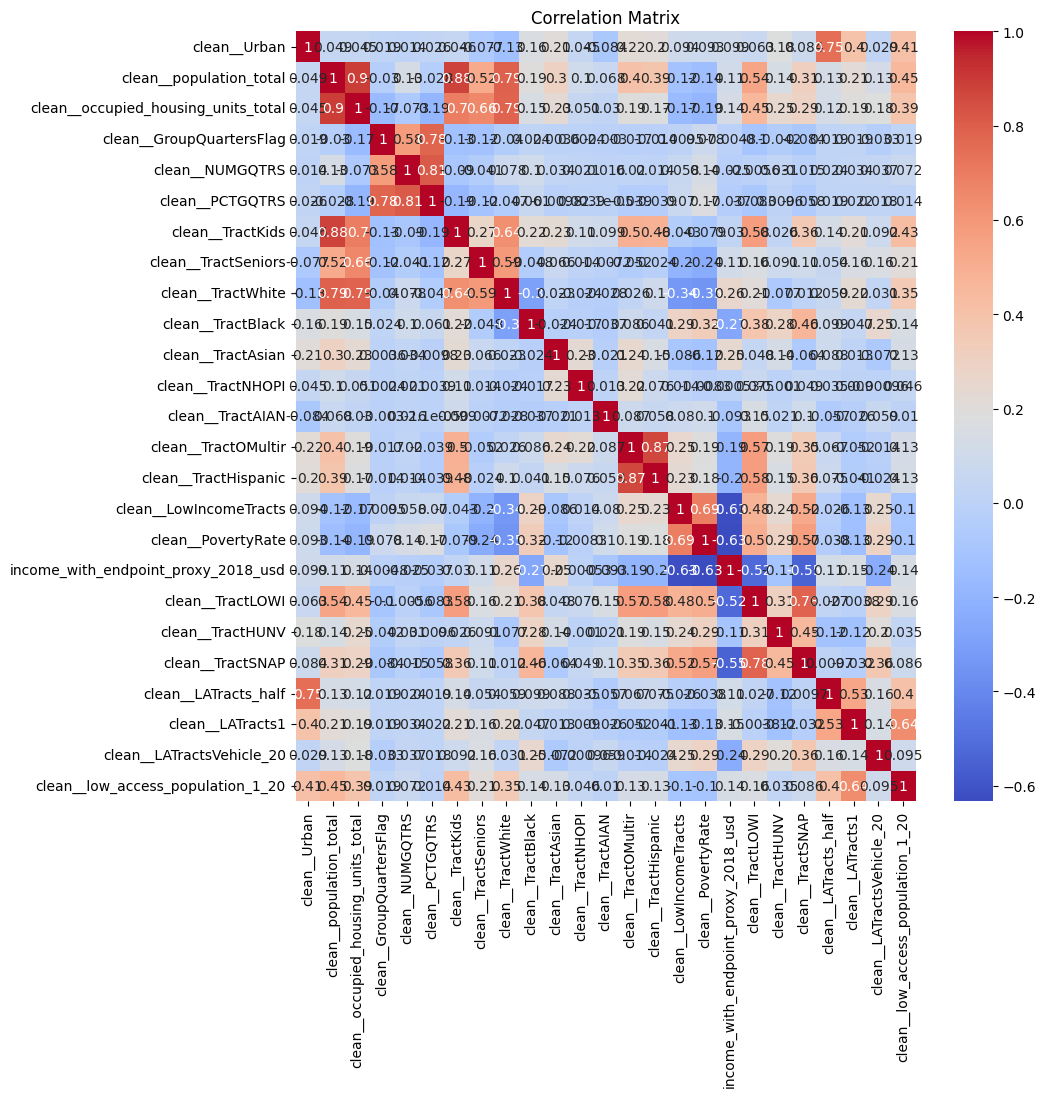

In [7]:
df_2019_x = df_2019.drop(columns=['tract_id'])

corr_matrix = df_2019_x.corr()

plt.figure(figsize=(10, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [8]:
corr_threshold = 0.80

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column].abs() > corr_threshold)
]

print(high_corr_features)

['clean__occupied_housing_units_total', 'clean__PCTGQTRS', 'clean__TractKids', 'clean__TractHispanic']


## VIF Analysis: Multicollinearity

In [9]:
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor


X = df_2019_x.copy()

X = X.fillna(X.median())

X = add_constant(X)

vif_data = pd.DataFrame()

vif_data["Feature"] = X.columns

vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

vif_data = vif_data[vif_data["Feature"] != "const"]

print(vif_data.sort_values("VIF", ascending=False))

/tmp/ipykernel_1495/1095735244.py:16: UserWarning: The design matrix is poorly conditioned (condition number=1.01e+16). VIF calculations may be numerically unstable.
  variance_inflation_factor(X.values, i)
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: 

                                Feature           VIF
2               clean__population_total  1.000800e+15
9                     clean__TractWhite  1.000800e+15
12                    clean__TractNHOPI  1.000800e+15
11                    clean__TractAsian  1.000800e+15
14                  clean__TractOMultir  1.000800e+15
13                     clean__TractAIAN  1.000800e+15
10                    clean__TractBlack  1.000800e+15
3   clean__occupied_housing_units_total  2.761677e+01
7                      clean__TractKids  2.112650e+01
5                       clean__NUMGQTRS  6.993808e+00
19                     clean__TractLOWI  6.428619e+00
6                       clean__PCTGQTRS  5.297035e+00
15                 clean__TractHispanic  5.281872e+00
21                     clean__TractSNAP  3.921207e+00
1                          clean__Urban  3.811335e+00
22                 clean__LATracts_half  3.429008e+00
17                   clean__PovertyRate  3.027677e+00
4              clean__GroupQ

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


Keeping all variables based on whether or not VIP > 8.

## K-Means Model with ALL Columns

In [25]:
# pipeline, standardize
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline

X = df_2019_x

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ))
])

X_train = X

pipeline.fit(X_train) #fitting in standardized pipeline

df_2019_x['cluster_group'] = pipeline.predict(X_train)

print(df_2019_x['cluster_group'].value_counts().sort_index())

cluster_group
0    19681
1    33863
2    18983
Name: count, dtype: int64


In [11]:
df_2019_x.groupby('cluster_group')[df_2019_x.columns].mean().round(2)

,clean__Urban,clean__population_total,clean__occupied_housing_units_total,clean__GroupQuartersFlag,clean__NUMGQTRS,clean__PCTGQTRS,clean__TractKids,clean__TractSeniors,clean__TractWhite,clean__TractBlack,...,clean__PovertyRate,income_with_endpoint_proxy_2018_usd,clean__TractLOWI,clean__TractHUNV,clean__TractSNAP,clean__LATracts_half,clean__LATracts1,clean__LATractsVehicle_20,clean__low_access_population_1_20,cluster_group
cluster_group,,,,,,,,,,,,,,,,,,,,,
0,0.89,5913.71,2251.16,0.00,93.23,1.50,1429.56,809.27,4789.66,376.86,...,7.81,100031.00,1272.46,115.0,151.43,0.86,0.67,0.21,2292.15,0.0
1,0.90,4677.52,1669.03,0.00,139.98,2.85,1234.12,493.62,2449.08,1175.07,...,27.48,46161.12,2448.44,275.9,407.55,0.71,0.29,0.46,1239.57,1.0
2,0.61,3022.62,1189.35,0.01,103.37,3.36,658.70,437.12,2412.71,272.81,...,12.68,80498.69,852.85,86.4,115.92,0.47,0.16,0.08,530.48,2.0


cluster group
*   0: low-risk
*   1: high-risk
*   2: medium-risk



In [12]:
from sklearn.metrics import silhouette_score


pipeline.fit(X_train)

#silhouette evaluation
X_scaled = pipeline[:-1].transform(X_train)

df_2019_x['cluster_group'] = pipeline.predict(X_train)

# Calculate silhouette score
silhouette_kmeans_full_model = silhouette_score(
    X_scaled,
    df_2019_x['cluster_group'] # clusters from original model
)

print("Silhouette Score:", silhouette_kmeans_full_model)

Silhouette Score: 0.19568836857905397


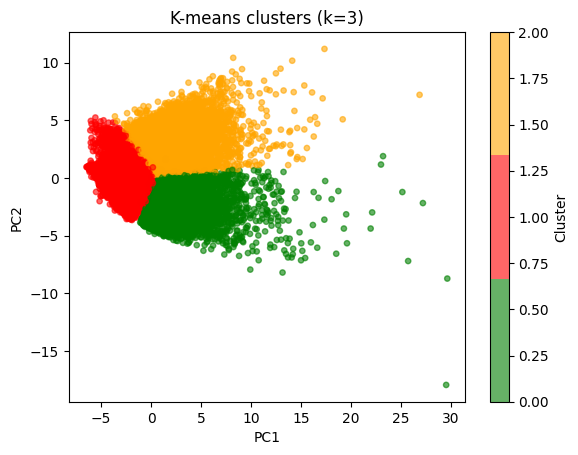

Explained variance ratio: [0.21791512 0.16441493]
Total explained variance: 0.38233005891833427


In [13]:
#PCA with all columns

from matplotlib.colors import ListedColormap

pca_allcols = PCA(n_components=2)
pcs_allcols = pca_allcols.fit_transform(X_scaled)


cmap_x = ListedColormap(['green', 'red', 'orange'])
plt.scatter(pcs_allcols[:, 0],
            pcs_allcols[:, 1],
            c=df_2019_x['cluster_group'],
            cmap=cmap_x, alpha=0.6, s=15)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-means clusters (k=3)')
plt.colorbar(label='Cluster')

plt.show()

print("Explained variance ratio:", pca_allcols.explained_variance_ratio_)

print("Total explained variance:", sum(pca_allcols.explained_variance_ratio_))

## K-Means Model with Non Binary Columns

In [14]:
# model with numerical non binary columns ONLY
#clean_urban, clean_lowincometracts,
#clean__TractLOWI, clean__TractHUNV clean__TractSNAP,
#'clean__LATracts_half','clean__LATracts1',

df_2019_x.columns.tolist()

features_2 = ['clean__population_total',
 'clean__occupied_housing_units_total',
 'clean__GroupQuartersFlag',
 'clean__NUMGQTRS',
 'clean__PCTGQTRS',
 'clean__TractKids',
 'clean__TractSeniors',
 'clean__TractWhite',
 'clean__TractBlack',
 'clean__TractAsian',
 'clean__TractNHOPI',
 'clean__TractAIAN',
 'clean__TractOMultir',
 'clean__TractHispanic',
 'clean__PovertyRate',
 'income_with_endpoint_proxy_2018_usd',
 'clean__LATractsVehicle_20']



In [26]:
X_train_2 = df_2019_x[features_2].copy()

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ))
])


pipeline.fit(X_train_2) #fitting in standardized pipeline

df_2019_x['cluster_group_2'] = pipeline.predict(X_train_2)

print(df_2019_x['cluster_group_2'].value_counts().sort_index())

cluster_group_2
0    46182
1    25826
2      519
Name: count, dtype: int64


In [16]:
X2_scaled = pipeline[:-1].transform(X_train_2)

silhouette_kmeans_model_2 = silhouette_score(
    X2_scaled,
    df_2019_x['cluster_group_2']
)

print("Silhouette Score:", silhouette_kmeans_model_2)

Silhouette Score: 0.23242273778818237


## Implementing PCA

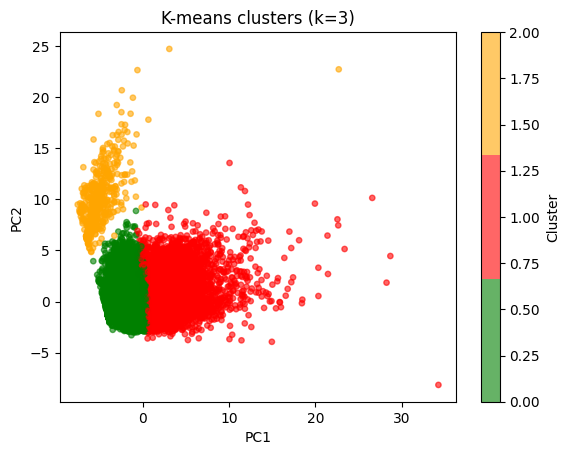

Explained variance ratio: [0.24765526 0.15666794]
Total explained variance: 0.40432319143618156


In [17]:
#PCA with non binary columns

from matplotlib.colors import ListedColormap

pca_nonbinary = PCA(n_components=2)
pcs_nonbinary = pca_nonbinary.fit_transform(X2_scaled)


cmap_x = ListedColormap(['green', 'red', 'orange'])
plt.scatter(pcs_nonbinary[:, 0],
            pcs_nonbinary[:, 1],
            c=df_2019_x['cluster_group_2'],
            cmap=cmap_x, alpha=0.6, s=15)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-means clusters (k=3)')
plt.colorbar(label='Cluster')

plt.show()

print("Explained variance ratio:", pca_nonbinary.explained_variance_ratio_)

print("Total explained variance:", sum(pca_nonbinary.explained_variance_ratio_))

In [18]:
# evaluating pca model clustering improvement with silhouette score

kmeans_pca = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters_pca = kmeans_pca.fit_predict(pcs_nonbinary)


silhouette_pca = silhouette_score(
    pcs_nonbinary,
    clusters_pca
)

print("PCA Silhouette Score:", silhouette_pca)


PCA Silhouette Score: 0.3684897729518543


In [19]:
pd.Series(clusters_pca).value_counts().sort_index()

,count
0,39018
1,20579
2,12930


In [20]:
#categorize clusers with original data

#removing original clusters

df_2019_x_upd = df_2019_x.drop(
    columns=['cluster_group', 'cluster_group_2'],
    errors='ignore'
).copy()

# Add new PCA cluster assignments
df_2019_x_upd['PCA_Cluster'] = clusters_pca

# Calculate cluster averages using original data
cluster_profile = df_2019_x_upd.groupby('PCA_Cluster').mean()

print(cluster_profile.round(2))

             clean__Urban  clean__population_total  \
PCA_Cluster                                          
0                    0.69                  3305.46   
1                    0.79                  6528.55   
2                    0.91                  3511.31   

             clean__occupied_housing_units_total  clean__GroupQuartersFlag  \
PCA_Cluster                                                                  
0                                        1336.04                      0.00   
1                                        2408.69                      0.00   
2                                        1161.13                      0.04   

             clean__NUMGQTRS  clean__PCTGQTRS  clean__TractKids  \
PCA_Cluster                                                       
0                      37.63             1.14            738.36   
1                      85.66             1.28           1655.64   
2                     367.66             9.70            873.34   

  

In [21]:
# use this model

# USING ONLY NONBINARY FEATURES
features_2 = ['clean__population_total',
 'clean__occupied_housing_units_total',
 'clean__GroupQuartersFlag',
 'clean__NUMGQTRS',
 'clean__PCTGQTRS',
 'clean__TractKids',
 'clean__TractSeniors',
 'clean__TractWhite',
 'clean__TractBlack',
 'clean__TractAsian',
 'clean__TractNHOPI',
 'clean__TractAIAN',
 'clean__TractOMultir',
 'clean__TractHispanic',
 'clean__PovertyRate',
 'income_with_endpoint_proxy_2018_usd',
 'clean__LATractsVehicle_20']



In [27]:

model_cols = features_2    # used for pcs_nonbinary

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2)),
    ("kmeans", KMeans(n_clusters=3, random_state=42, n_init=10)),
])

labels = pipe.fit_predict(df_2019_x[model_cols])


# checking if model is being reproduced

print("Exact match:", (labels == clusters_pca).mean())
print("ARI vs original:", adjusted_rand_score(clusters_pca, labels))
print("Silhouette:", silhouette_score(pipe[:-1].transform(df_2019_x[model_cols]), labels))

Exact match: 1.0
ARI vs original: 1.0
Silhouette: 0.3684897729518543


In [28]:
bundle = {
    "pipeline": pipe,
    "model_cols": model_cols,
    "id_col": "tract_id",
    "risk_map": {0: 0, 1: 1, 2: 2},
    "risk_names": {0: "Low", 1: "High", 2: "Medium"},
}

with open("cluster_model.pkl", "wb") as f:
    pickle.dump(bundle, f)